In [57]:
import os
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

data_path = Path("/kaggle/input/satellite-image-classification/data")

print(os.listdir(data_path))

['cloudy', 'desert', 'green_area', 'water']


In [58]:
images = []
labels = []

for category in os.listdir(data_path):
    folder = data_path / category

    if folder.is_dir():
        for file in folder.glob("*.jpg"):
            images.append(str(file))
            labels.append(category)

df = pd.DataFrame({
    "image_path": images,
    "label": labels
})


In [59]:
print(df.shape)

(5631, 2)


In [60]:
print(df["label"].value_counts())

label
cloudy        1500
green_area    1500
water         1500
desert        1131
Name: count, dtype: int64


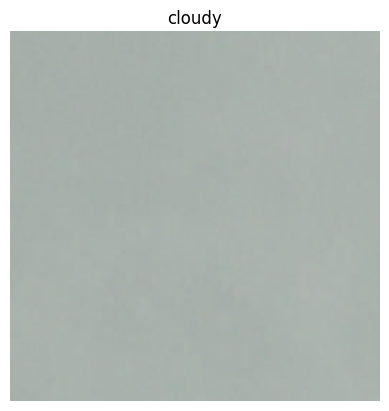

In [61]:
image = Image.open(df.iloc[0]["image_path"])

plt.imshow(image)
plt.title(df.iloc[0]["label"])
plt.axis("off")
plt.show()

## Detect and remove duplicates


In [62]:
print(df.columns.tolist())
print(df.head())

['image_path', 'label']
                                          image_path   label
0  /kaggle/input/satellite-image-classification/d...  cloudy
1  /kaggle/input/satellite-image-classification/d...  cloudy
2  /kaggle/input/satellite-image-classification/d...  cloudy
3  /kaggle/input/satellite-image-classification/d...  cloudy
4  /kaggle/input/satellite-image-classification/d...  cloudy


In [63]:
from pathlib import Path
import hashlib
df = df.rename(columns={"image_path": "path"})

def image_hash(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        h = hashlib.sha256()
        h.update(str(img.size).encode())
        h.update(img.tobytes())
        return h.hexdigest()

df["hash"] = df["path"].apply(image_hash)

duplicates = df[df.duplicated(
    subset="hash",
    keep=False
)]

print("Duplicate image records:", len(duplicates))
print("Extra duplicate copies:", df.duplicated("hash").sum())

display(duplicates.sort_values("hash").head(20))

Duplicate image records: 78
Extra duplicate copies: 39


,path,label,hash
2414,/kaggle/input/satellite-image-classification/d...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
1917,/kaggle/input/satellite-image-classification/d...,desert,039a6a6a9eca9fc558043dea4ed7f266b5d1da0ddb2bcf...
1586,/kaggle/input/satellite-image-classification/d...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
1833,/kaggle/input/satellite-image-classification/d...,desert,0d57fa3122f6e7e3d20c42dacbe607376b6d193dd28377...
2432,/kaggle/input/satellite-image-classification/d...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2288,/kaggle/input/satellite-image-classification/d...,desert,10a96767c6f42d095e5ab3ea305c67979c5b2b4bb71f12...
2259,/kaggle/input/satellite-image-classification/d...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
2103,/kaggle/input/satellite-image-classification/d...,desert,1162e1b91250bbc1f82959e53fd28c195f8b7a476ded8f...
1915,/kaggle/input/satellite-image-classification/d...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...
1945,/kaggle/input/satellite-image-classification/d...,desert,175735f9142ed0e8b684d78d677f70fffbfa0be9830c90...


Original images	5,631

Extra duplicate copies	39

Expected images after removal	5,592

In [64]:
conflicts = df.groupby("hash")["label"].nunique()

conflicting_hashes = conflicts[conflicts > 1]

print("Conflicting label groups:", len(conflicting_hashes))

Conflicting label groups: 0


In [65]:
df_clean = df.drop_duplicates(
    subset="hash",
    keep="first"
).reset_index(drop=True)

print("Before:", len(df))
print("After:", len(df_clean))
print("Removed:", len(df) - len(df_clean))

Before: 5631
After: 5592
Removed: 39


## dataset splitting


In [66]:
from sklearn.model_selection import train_test_split

# first take 70% for training, the other 30% is split in half
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["label"]
)

# half of the 30% -> validation, the other half -> test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 3914
Validation: 839
Testing: 839


## Standardize image dimensions

In [67]:
def resize_images(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        with Image.open(row["path"]) as img:
            img = img.convert("RGB")
            img = img.resize(
                (64, 64),
                Image.Resampling.LANCZOS
            )
            images.append(np.array(img))
            labels.append(row["label"])

    return np.array(images), np.array(labels)

X_train, y_train = resize_images(train_df)
X_val, y_val = resize_images(val_df)
X_test, y_test = resize_images(test_df)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (3914, 64, 64, 3)
Validation shape: (839, 64, 64, 3)
Testing shape: (839, 64, 64, 3)


## Normalize pixel values

In [68]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Min:", X_train.min())
print("Max:", X_train.max())
print("Shape:", X_train.shape)

Min: 0.023529412
Max: 1.0
Shape: (3914, 64, 64, 3)


In [69]:
# Flatten images into 2D arrays

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Testing shape:", X_test_flat.shape)

Training shape: (3914, 12288)
Validation shape: (839, 12288)
Testing shape: (839, 12288)


In [70]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

print("Classes:", encoder.classes_)

Classes: ['cloudy' 'desert' 'green_area' 'water']


## Feature extraction


In [71]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# scale pixels (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_val_scaled = scaler.transform(X_val_flat)
X_test_scaled = scaler.transform(X_test_flat)

# PCA (fit on train only)
pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original:", X_train_flat.shape)
print("After PCA:", X_train_pca.shape)
print("Variance retained:", pca.explained_variance_ratio_.sum())

Original: (3914, 12288)
After PCA: (3914, 100)
Variance retained: 0.9958497


In [72]:
# color histogram: 16 bins for each of the R, G, B channels
def color_hist(images, bins=16):
    feats = []
    for img in images:
        h = [np.histogram(img[:, :, c], bins=bins, range=(0, 1))[0] for c in range(3)]
        feats.append(np.concatenate(h) / (img.shape[0] * img.shape[1]))
    return np.array(feats)

X_train_feat = np.hstack([X_train_pca, color_hist(X_train)])
X_val_feat = np.hstack([X_val_pca, color_hist(X_val)])
X_test_feat = np.hstack([X_test_pca, color_hist(X_test)])

# scale the combined features so PCA and histogram values are on the same level
final_scaler = StandardScaler()
X_train_final = final_scaler.fit_transform(X_train_feat)
X_val_final = final_scaler.transform(X_val_feat)
X_test_final = final_scaler.transform(X_test_feat)

print("Final feature shape:", X_train_final.shape)

Final feature shape: (3914, 148)


In [83]:
# Recreate the PCA representation that helped KNN in the old notebook.
# DO NOT overwrite 'pca' from the existing PCA+histogram pipeline.
pca_raw = PCA(n_components=100, random_state=42)
X_train_pca_raw = pca_raw.fit_transform(X_train_flat)
X_val_pca_raw = pca_raw.transform(X_val_flat)
X_test_pca_raw = pca_raw.transform(X_test_flat)

feature_options = {
    "PCA on normalized pixels ": (
        X_train_pca_raw, X_val_pca_raw, X_test_pca_raw
    ),
    "Scaled PCA + color histograms": (
        X_train_final, X_val_final, X_test_final
    ),
}
print("Prepared feature representations:")
for name, (tr, va, te) in feature_options.items():
    print(name, tr.shape, va.shape, te.shape)


Prepared feature representations:
PCA on normalized pixels  (3914, 100) (839, 100) (839, 100)
Scaled PCA + color histograms (3914, 148) (839, 148) (839, 148)


## Tune the models on the validation set

In [93]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# try different C values, pick the best one on the validation set
best_C, best_val = None, 0

for C in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=2000, random_state=42)
    model.fit(X_train_final, y_train_encoded)
    acc = accuracy_score(y_val_encoded, model.predict(X_val_final))
    print(f"C = {C:<6} validation accuracy = {acc:.4f}")
    if acc > best_val:
        best_C, best_val = C, acc

print("Best C:", best_C)
logistic_model = model
logistic_X_test = Xte

logistic_model = LogisticRegression(C=best_C, max_iter=2000, random_state=42)
logistic_model.fit(X_train_final, y_train_encoded)

C = 0.01   validation accuracy = 0.9058
C = 0.1    validation accuracy = 0.9201
C = 1      validation accuracy = 0.9094
C = 10     validation accuracy = 0.9082
C = 100    validation accuracy = 0.9058
Best C: 0.1


LogisticRegression(C=0.1, max_iter=2000, random_state=42)

In [85]:
from sklearn.neighbors import KNeighborsClassifier

# Compare the old KNN+PCA recipe with the newer combined representation.
# Select by validation accuracy; never select a configuration using test results.
knn_best_val = -1
for feat_name, (Xtr, Xva, Xte) in feature_options.items():
    for neighbors in [1, 3, 5, 7, 9, 11, 15, 21]:
        model = KNeighborsClassifier(
            n_neighbors=neighbors, weights="distance", n_jobs=-1
        )
        model.fit(Xtr, y_train_encoded)
        pred = model.predict(Xva)
        acc = accuracy_score(y_val_encoded, pred)
        print(f"KNN | {feat_name} | k={neighbors}: val accuracy={acc:.4f}")
        if acc > knn_best_val:
            knn_best_val = acc
            knn_model = model
            knn_feature_name = feat_name
            knn_X_test = Xte
            knn_neighbors = neighbors

print("\nSelected KNN features:", knn_feature_name)
print("Best neighbors:", knn_neighbors)
print("Best KNN validation accuracy:", knn_best_val)


KNN | PCA on normalized pixels  | k=1: val accuracy=0.9118
KNN | PCA on normalized pixels  | k=3: val accuracy=0.9190
KNN | PCA on normalized pixels  | k=5: val accuracy=0.9178
KNN | PCA on normalized pixels  | k=7: val accuracy=0.9237
KNN | PCA on normalized pixels  | k=9: val accuracy=0.9285
KNN | PCA on normalized pixels  | k=11: val accuracy=0.9261
KNN | PCA on normalized pixels  | k=15: val accuracy=0.9237
KNN | PCA on normalized pixels  | k=21: val accuracy=0.9213
KNN | Scaled PCA + color histograms | k=1: val accuracy=0.8033
KNN | Scaled PCA + color histograms | k=3: val accuracy=0.8105
KNN | Scaled PCA + color histograms | k=5: val accuracy=0.8284
KNN | Scaled PCA + color histograms | k=7: val accuracy=0.8331
KNN | Scaled PCA + color histograms | k=9: val accuracy=0.8260
KNN | Scaled PCA + color histograms | k=11: val accuracy=0.8212
KNN | Scaled PCA + color histograms | k=15: val accuracy=0.8188
KNN | Scaled PCA + color histograms | k=21: val accuracy=0.8141

Selected KNN feat

## K-Means (unsupervised)


In [86]:

from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
import numpy as np

best_accuracy = -1
best_k = None

# Try different numbers of clusters
for k in [4, 6, 8, 12, 16, 24]:

    model = KMeans(
        n_clusters=k,
        n_init=20,
        max_iter=300,
        random_state=42
    )

    train_clusters = model.fit_predict(X_train_final)

    # Map each cluster to its majority class
    mapping = {}

    for c in range(k):
        labels = y_train_encoded[train_clusters == c]
        mapping[c] = np.bincount(labels).argmax()

    # Evaluate on validation data
    val_clusters = model.predict(X_val_final)

    val_pred = np.array([
        mapping[c] for c in val_clusters
    ])

    acc = accuracy_score(y_val_encoded, val_pred)
    f1 = f1_score(y_val_encoded, val_pred, average="macro")

    print(f"Clusters: {k} | Accuracy: {acc:.4f} | F1: {f1:.4f}")

    if acc > best_accuracy:
        best_accuracy = acc
        best_k = k
        kmeans = model
        cluster_to_label = mapping.copy()
        kmeans_val_pred = val_pred.copy()

print("\nBest number of clusters:", best_k)
print("Best validation accuracy:", best_accuracy)

print("Cluster -> label:", {
    c: encoder.classes_[label]
    for c, label in cluster_to_label.items()
})

sil_score = silhouette_score(
    X_train_final,
    kmeans.labels_,
    sample_size=2000,
    random_state=42
)

print("Silhouette score:", sil_score)


Clusters: 4 | Accuracy: 0.5340 | F1: 0.3480
Clusters: 6 | Accuracy: 0.5662 | F1: 0.4257
Clusters: 8 | Accuracy: 0.6079 | F1: 0.5667
Clusters: 12 | Accuracy: 0.7271 | F1: 0.7024
Clusters: 16 | Accuracy: 0.7080 | F1: 0.6937
Clusters: 24 | Accuracy: 0.7247 | F1: 0.7168

Best number of clusters: 12
Best validation accuracy: 0.7270560190703218
Cluster -> label: {0: np.str_('water'), 1: np.str_('cloudy'), 2: np.str_('cloudy'), 3: np.str_('water'), 4: np.str_('cloudy'), 5: np.str_('cloudy'), 6: np.str_('green_area'), 7: np.str_('cloudy'), 8: np.str_('cloudy'), 9: np.str_('cloudy'), 10: np.str_('cloudy'), 11: np.str_('desert')}
Silhouette score: 0.05874398328603115


In [87]:
from sklearn.metrics import accuracy_score, f1_score

test_clusters = kmeans.predict(X_test_final)

kmeans_test_pred = np.array([
    cluster_to_label[c] for c in test_clusters
])

print("Test Accuracy:",
      accuracy_score(y_test_encoded, kmeans_test_pred))

print("Test Macro F1:",
      f1_score(y_test_encoded, kmeans_test_pred, average="macro"))

Test Accuracy: 0.734207389749702
Test Macro F1: 0.7155884745068889


In [94]:
from sklearn.metrics import classification_report, f1_score

# The supervised models may use DIFFERENT feature representations.
logistic_pred = logistic_model.predict(logistic_X_test)
knn_pred = knn_model.predict(knn_X_test)

# K-Means always uses the unchanged combined features.
kmeans_pred = np.array([
    cluster_to_label[c] for c in kmeans.predict(X_test_final)
])

for name, pred in [
    ("LOGISTIC REGRESSION", logistic_pred),
    ("KNN", knn_pred),
    ("K-MEANS (mapped clusters)", kmeans_pred),
]:
    print(name)
    print("Accuracy:", accuracy_score(y_test_encoded, pred))
    print(classification_report(y_test_encoded, pred, target_names=encoder.classes_))
    print()


LOGISTIC REGRESSION
Accuracy: 0.9046483909415971
              precision    recall  f1-score   support

      cloudy       0.95      0.94      0.95       225
      desert       0.96      0.95      0.95       164
  green_area       0.86      0.88      0.87       225
       water       0.86      0.87      0.86       225

    accuracy                           0.90       839
   macro avg       0.91      0.91      0.91       839
weighted avg       0.91      0.90      0.90       839


KNN
Accuracy: 0.9284862932061978
              precision    recall  f1-score   support

      cloudy       0.96      0.96      0.96       225
      desert       0.97      0.95      0.96       164
  green_area       0.93      0.88      0.90       225
       water       0.87      0.94      0.90       225

    accuracy                           0.93       839
   macro avg       0.93      0.93      0.93       839
weighted avg       0.93      0.93      0.93       839


K-MEANS (mapped clusters)
Accuracy: 0.73420738

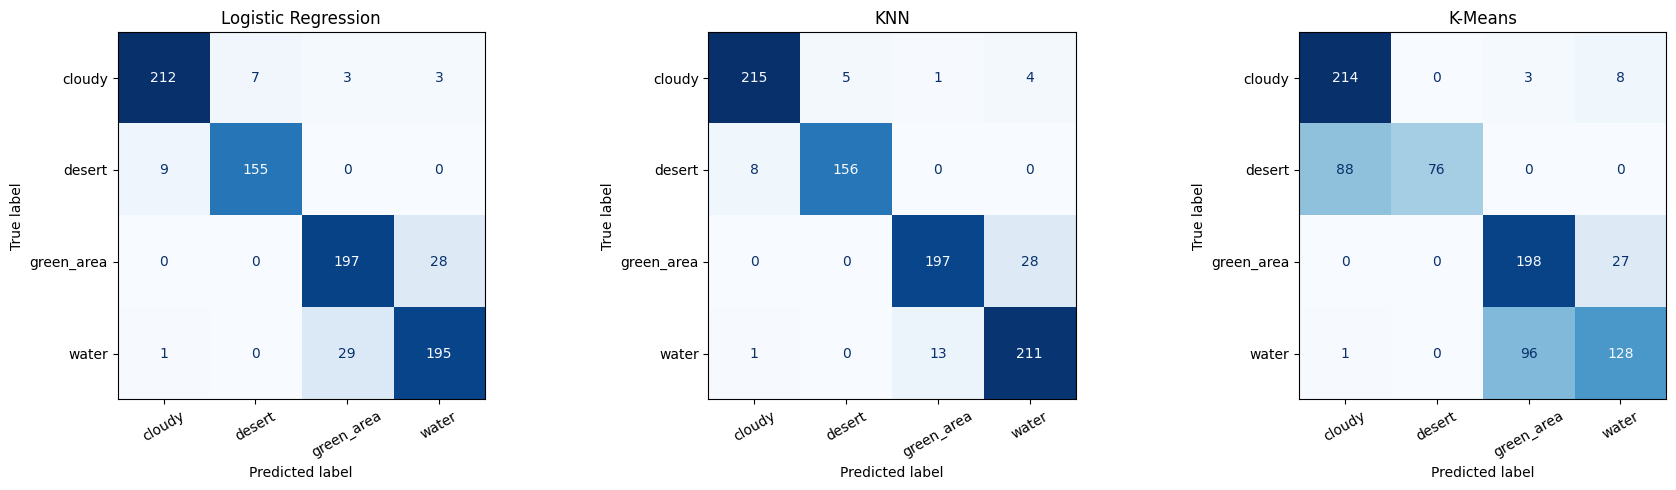

In [95]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name, pred in zip(axes,
                          ["Logistic Regression", "KNN", "K-Means"],
                          [logistic_pred, knn_pred, kmeans_pred]):
    ConfusionMatrixDisplay.from_predictions(
        y_test_encoded, pred,
        display_labels=encoder.classes_,
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

,Model,Accuracy,F1 Score (Macro)
1,KNN,0.928486,0.930766
0,Logistic Regression,0.904648,0.908013
2,K-Means,0.734207,0.715588


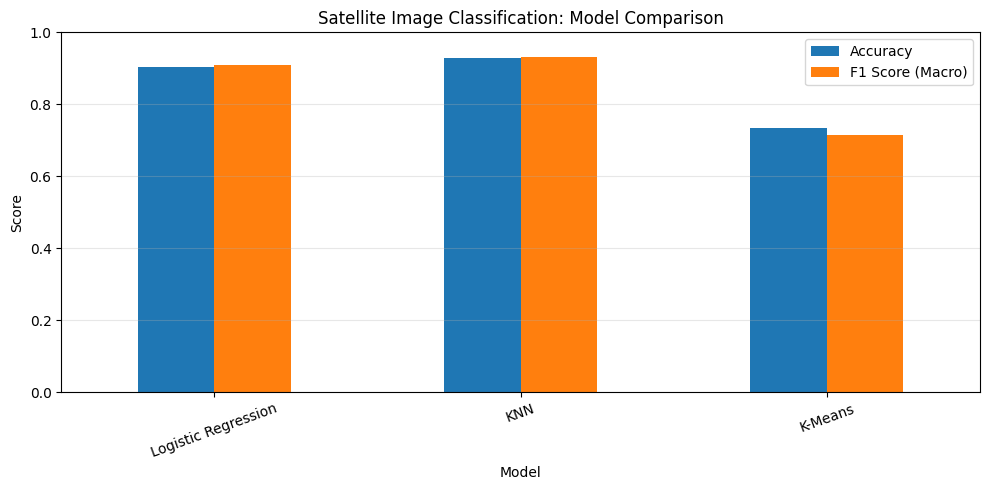

In [96]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "K-Means"],
    "Accuracy": [
        accuracy_score(y_test_encoded, logistic_pred),
        accuracy_score(y_test_encoded, knn_pred),
        accuracy_score(y_test_encoded, kmeans_pred)
    ],
    "F1 Score (Macro)": [
        f1_score(y_test_encoded, logistic_pred, average="macro"),
        f1_score(y_test_encoded, knn_pred, average="macro"),
        f1_score(y_test_encoded, kmeans_pred, average="macro")
    ]
})

display(results.sort_values("Accuracy", ascending=False))

results.plot(
    x="Model",
    y=["Accuracy", "F1 Score (Macro)"],
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Satellite Image Classification: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

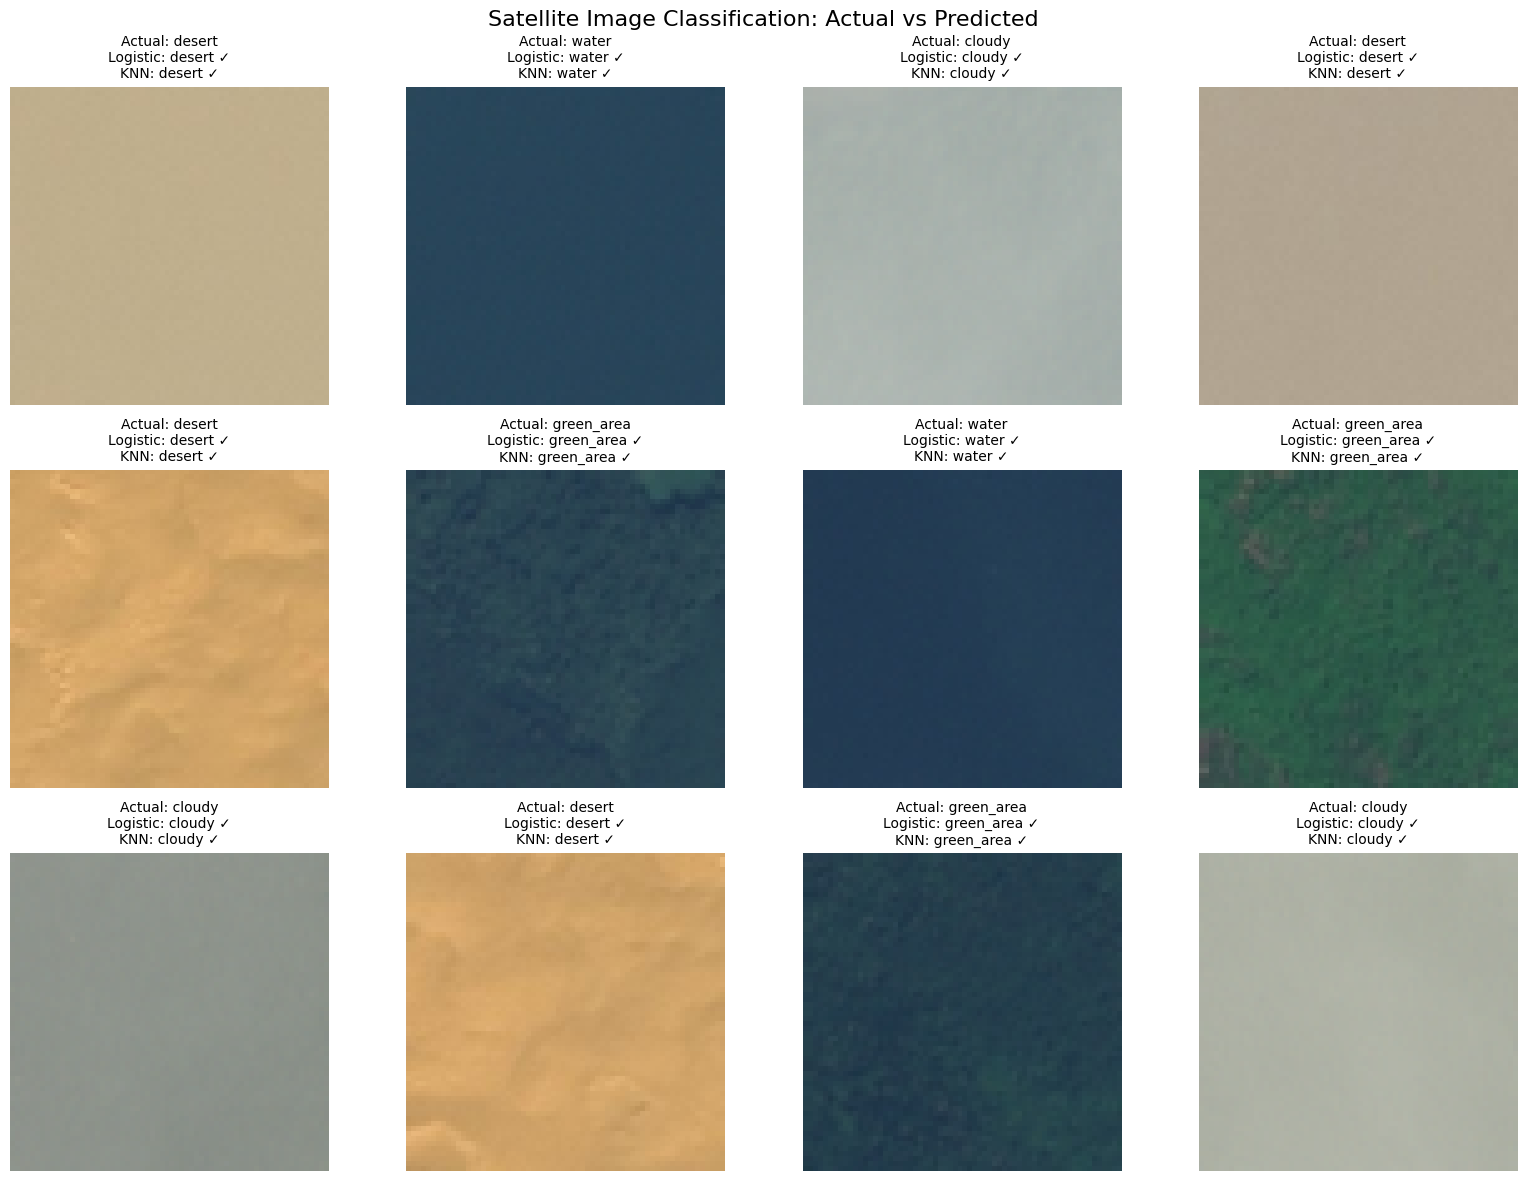

In [97]:
# Select 12 random test images
rng = np.random.default_rng(42)
indices = rng.choice(len(X_test), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, i in zip(axes.flat, indices):

    # Original normalized image (not PCA features)
    image = X_test[i]

    actual = encoder.inverse_transform([y_test_encoded[i]])[0]
    logistic_label = encoder.inverse_transform([logistic_pred[i]])[0]
    knn_label = encoder.inverse_transform([knn_pred[i]])[0]

    ax.imshow(image)

    # Show predictions from both models
    ax.set_title(
        f"Actual: {actual}\n"
        f"Logistic: {logistic_label} "
        f"{'✓' if actual == logistic_label else '✗'}\n"
        f"KNN: {knn_label} "
        f"{'✓' if actual == knn_label else '✗'}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Satellite Image Classification: Actual vs Predicted",
    fontsize=16
)
plt.tight_layout()
plt.show()

## for GUI


In [98]:
import joblib

os.makedirs("saved_models", exist_ok=True)

joblib.dump(encoder, "saved_models/label_encoder.joblib")
joblib.dump(scaler, "saved_models/scaler.joblib")
joblib.dump(pca, "saved_models/pca.joblib")
joblib.dump(final_scaler, "saved_models/final_scaler.joblib")
joblib.dump(logistic_model, "saved_models/logistic_model.joblib")
joblib.dump(knn_model, "saved_models/knn_model.joblib")
joblib.dump(kmeans, "saved_models/kmeans_model.joblib")
joblib.dump(cluster_to_label, "saved_models/cluster_to_label.joblib")

print(os.listdir("saved_models"))

['logistic_model.joblib', 'scaler.joblib', 'label_encoder.joblib', 'cluster_to_label.joblib', 'knn_model.joblib', 'pca.joblib', 'kmeans_model.joblib', 'final_scaler.joblib']
